# Gradient Boosting Model

How effectively can Gradient Boosting predict the average attainment 8 score of a school, and how does its predictive accuracy compare with the group's Linear Regression and Random Forest models?
Gradient Boosting builds a model by adding trees sequentially, with each new tree trying to correct errors made by the previous ones[1].
We extracted some columns from the original dataset to create a training/test split. All model selection and 5-fold cross-validation happen only on training data. We evaluate the final chosen model once on the test data. The main comparison metric is RMSE; AIC is examined critically as an additional complexity-sensitive measure.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import KFold, GroupKFold, GridSearchCV, cross_validate
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

RANDOM_STATE = 42
train_data = pd.read_csv('attainment8_train.csv')
test_data = pd.read_csv('attainment8_test.csv')
print('Training shape:', train_data.shape)
print('Test shape:', test_data.shape)
print('Years in training:', sorted(train_data.time_period.unique()))
print('Years in test:', sorted(test_data.time_period.unique()))

Training shape: (7873, 78)
Test shape: (1969, 78)
Years in training: [np.int64(202324), np.int64(202425), np.int64(202526)]
Years in test: [np.int64(202324), np.int64(202425), np.int64(202526)]


### Experiment: Does using more predictors improve Gradient Boosting?

Before building our final Gradient Boosting model, we investigated whether the number of predictors affected prediction accuracy.
We compared two sets of input variables. The first contained **10 school and pupil characteristics**, including pupil numbers, school admission type and the percentage of disadvantaged pupils. This provided a smaller starting model using variables that were straightforward to interpret.
The second contained **23 predictors**, selected from the 30 variables initially considered in our group's Linear Regression and Random Forest models. We excluded four exam-entry variables (`gcse_entries_average`, `qual_entries_average`, `sci_triple_entering_percent` and `lan_multiple_entering_percent`) because they describe academic activity closely related to the outcome. We also excluded academic year and geographical names (`time_period`, `la_name` and `pcon_name`) to focus on school and pupil characteristics.
To compare the two sets fairly, we used the same baseline Gradient Boosting settings (**100 trees, learning rate 0.1 and maximum depth 3**), the same training data and the same five cross-validation folds. Missing-value imputation and categorical encoding were carried out within each fold.
This experiment allowed us to assess whether the broader predictor set improved accuracy before deciding which variables to use in the rest of the notebook. The test dataset was not used to make this decision.

In [2]:
# Compare a broader, leakage-screened predictor set with our original 10.
# This experiment uses separate variable names and does not change the main model below.
from sklearn.model_selection import KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import GradientBoostingRegressor
import pandas as pd
import numpy as np

comparison_target = 'attainment8_average'
comparison_small_numeric = [
    'allks_pupil_count', 'min_age', 'max_age',
    'sen_pupil_percent', 'sen_with_ehcp_pupil_percent',
    'ks4_disadvantaged_pupil_percent',
    'ks4_first_language_other_than_english_pupil_percent'
]
comparison_small_categorical = [
    'establishment_type_group', 'school_admission_type', 'sex_policy'
]
comparison_small = comparison_small_numeric + comparison_small_categorical

# 30 original groupmate predictors, excluding 4 academic-entry measures
# and 3 year/geographical variables = 23 predictors.
comparison_broad = [
    'establishment_type_group', 'school_admission_type',
    'school_religious_character_detailed', 'sex_policy',
    'min_age', 'max_age', 'allks_pupil_count', 'endks4_pupil_count',
    'sen_pupil_count', 'sen_pupil_percent',
    'sen_with_ehcp_pupil_count', 'sen_with_ehcp_pupil_percent',
    'sen_no_ehcp_pupil_count', 'sen_no_ehcp_pupil_percent',
    'pupil_count', 'ks4_disadvantaged_pupil_count',
    'ks4_disadvantaged_pupil_percent',
    'ks4_not_known_disadvantaged_pupil_count',
    'ks4_not_known_disadvantaged_pupil_percent',
    'ks4_first_language_other_than_english_pupil_count',
    'ks4_first_language_other_than_english_pupil_percent',
    'ks4_non_mobile_pupil_count', 'ks4_non_mobile_pupil_percent'
]
assert len(comparison_small) == 10 and len(comparison_broad) == 23
assert set(comparison_small).issubset(comparison_broad)
assert set(comparison_broad + [comparison_target]).issubset(train_data.columns)

comparison_cv = KFold(n_splits=5, shuffle=True, random_state=42)

def compare_predictor_set(columns, categorical):
    numeric = [c for c in columns if c not in categorical]
    preprocessing = ColumnTransformer([
        ('numeric', SimpleImputer(strategy='median'), numeric),
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), categorical)
    ])
    model = Pipeline([
        ('preprocess', preprocessing),
        ('model', GradientBoostingRegressor(
            n_estimators=100, learning_rate=0.1, max_depth=3,
            subsample=1.0, random_state=42
        ))
    ])
    scores = cross_validate(
        model, train_data[columns], train_data[comparison_target],
        cv=comparison_cv, scoring='neg_root_mean_squared_error', n_jobs=-1
    )
    return -scores['test_score']

comparison_broad_categorical = [
    'establishment_type_group', 'school_admission_type',
    'school_religious_character_detailed', 'sex_policy'
]
comparison_small_rmse = compare_predictor_set(
    comparison_small, comparison_small_categorical
)
comparison_broad_rmse = compare_predictor_set(
    comparison_broad, comparison_broad_categorical
)

comparison_results = pd.DataFrame({
    'Predictor set': ['Original 10 predictors', 'Broader 23 predictors'],
    'Number of predictors': [10, 23],
    'Mean CV RMSE': [comparison_small_rmse.mean(), comparison_broad_rmse.mean()],
    'Fold RMSE SD': [comparison_small_rmse.std(ddof=1), comparison_broad_rmse.std(ddof=1)]
})
print('Comparison using identical baseline Gradient Boosting settings:')
print(comparison_results.round(3).to_string(index=False))
print('RMSE difference (broader minus original):',
      round(comparison_broad_rmse.mean() - comparison_small_rmse.mean(), 3))


Comparison using identical baseline Gradient Boosting settings:
         Predictor set  Number of predictors  Mean CV RMSE  Fold RMSE SD
Original 10 predictors                    10         5.047         0.116
 Broader 23 predictors                    23         4.753         0.126
RMSE difference (broader minus original): -0.294


## Predictor-set comparison: Results 
The original 10-predictor model achieved a mean five-fold cross-validation RMSE of 5.047, compared with 4.753 for the broader 23-predictor model. Adding the extra school and pupil characteristics reduced RMSE by 0.293 points (approximately 5.8%). The fold-to-fold standard deviations were approximately 0.117 and 0.126, respectively.
This suggests that our initial 10 predictors did not capture all the useful information available in the wider set. In particular, the broader model includes additional pupil counts and ks4_non_mobile_pupil_percent, although this experiment does not tell us which individual extra variable caused the improvement.

Decision and limitation: The broader predictor set performed better using the same baseline settings, so we selected the 23-predictor model for the remaining analysis. We then investigated whether hyperparameter tuning could improve its performance further.

Attainment 8 is built from English, maths, EBacc and open scores, so we cannot use those scores as predictors: that would practically give the model the answer. We also leave out GCSE results, Progress 8, exam-entry figures and subgroup Attainment 8 scores. Our comparison above found that the broader 23-predictor set performed better than the original 10, so we use those 23 school and pupil characteristics for the remaining Gradient Boosting analysis.

A limitation: these demographic fields are recorded alongside the outcome in this dataset. They are not necessarily known before the GCSE results. So this is best described as a school-context prediction exercise, rather than a proven real-world forecast. To claim a genuinely prospective forecast, we'd need earlier-year predictor data.

We also exclude school IDs, names, local authority IDs and year from the predictors. We keep school IDs and local authorities separately to test generalisation later.

In [3]:
target = 'attainment8_average'
# The broader 23-predictor set was compared against our original 10 above.
features = comparison_broad.copy()
categorical_features = comparison_broad_categorical.copy()
numeric_features = [col for col in features if col not in categorical_features]
assert len(features) == 23
assert set(features + [target, 'school_urn', 'new_la_code']).issubset(train_data.columns)
X_train = train_data[features].copy()
y_train = train_data[target].copy()
X_test = test_data[features].copy()
y_test = test_data[target].copy()
print('Selected predictors:', features)
print('Missing values in training predictors:')
print(X_train.isna().sum().to_string())
print('Missing outcomes:', y_train.isna().sum(), y_test.isna().sum())
assert y_train.notna().all() and y_test.notna().all()

Selected predictors: ['establishment_type_group', 'school_admission_type', 'school_religious_character_detailed', 'sex_policy', 'min_age', 'max_age', 'allks_pupil_count', 'endks4_pupil_count', 'sen_pupil_count', 'sen_pupil_percent', 'sen_with_ehcp_pupil_count', 'sen_with_ehcp_pupil_percent', 'sen_no_ehcp_pupil_count', 'sen_no_ehcp_pupil_percent', 'pupil_count', 'ks4_disadvantaged_pupil_count', 'ks4_disadvantaged_pupil_percent', 'ks4_not_known_disadvantaged_pupil_count', 'ks4_not_known_disadvantaged_pupil_percent', 'ks4_first_language_other_than_english_pupil_count', 'ks4_first_language_other_than_english_pupil_percent', 'ks4_non_mobile_pupil_count', 'ks4_non_mobile_pupil_percent']
Missing values in training predictors:
establishment_type_group                               0
school_admission_type                                  0
school_religious_character_detailed                    0
sex_policy                                             0
min_age                                    

We use a pipeline so that missing-value handling and one-hot encoding are fitted inside each training fold. This avoids letting information from the validation folds influence preprocessing.

In [4]:
preprocessor = ColumnTransformer([
    ('numeric', SimpleImputer(strategy='median'), numeric_features),
    ('categorical', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_features)
])

def make_model(**kwargs):
    settings = dict(random_state=RANDOM_STATE, n_estimators=100,
                    learning_rate=0.1, max_depth=3, subsample=1.0)
    settings.update(kwargs)
    return Pipeline([
        ('preprocess', preprocessor),
        ('model', GradientBoostingRegressor(**settings))
    ])

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def evaluate_cv(estimator, X, y, splitter=cv, groups=None):
    scores = cross_validate(estimator, X, y, cv=splitter, groups=groups,
                            scoring='neg_root_mean_squared_error',
                            return_train_score=True, n_jobs=-1)
    return (-scores['test_score'], -scores['train_score'])

Before fitting anything, we check the distribution of Attainment 8. Unusually high or low scores could be harder to predict, which we'll revisit in the residual analysis.

count    7873.00
mean       46.92
std         9.42
min         0.80
25%        40.90
50%        45.80
75%        51.10
max        87.30
Name: attainment8_average, dtype: float64


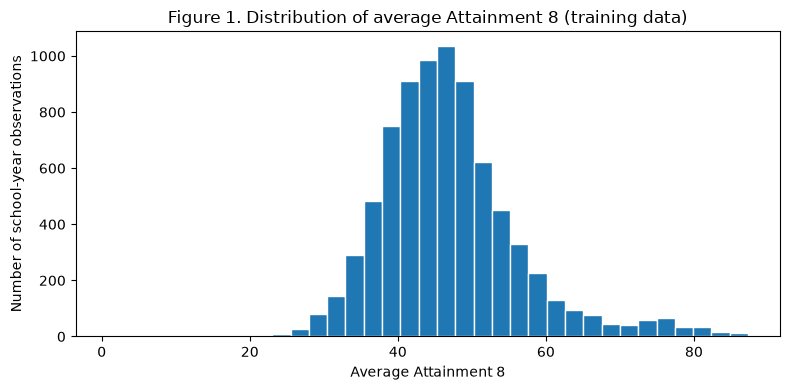

In [5]:
print(y_train.describe().round(2))
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(y_train, bins=35, edgecolor='white')
ax.set(title='Figure 1. Distribution of average Attainment 8 (training data)',
       xlabel='Average Attainment 8', ylabel='Number of school-year observations')
plt.tight_layout(); plt.show()

Figure 1 shows that most schools have Attainment 8 scores around the middle of the distribution, while fewer schools have very low or very high scores. The training data has an average score of approximately 46.9.

This suggests that predicting scores near the average may be easier than predicting schools with unusually high or low attainment. We will investigate this further when looking at the model's residuals.

## Choosing our Performance Metric
We use Root Mean Squared Error (RMSE) as our main performance metric. RMSE measures the difference between predicted and actual Attainment 8 scores, with larger errors receiving more weight.
This is useful because we want to identify models that make accurate predictions while avoiding very large errors for individual schools.
We also report Mean Absolute Error (MAE), which is easier to interpret as the average size of an error, and R², which shows how much of the variation in attainment the model explains.
Our group can use these metrics to compare Gradient Boosting with Linear Regression and Random Forest, provided the models are evaluated consistently.

## Fitting a basic Gradient Boosting model
Gradient Boosting builds lots of small trees in sequence. Each new tree tries to improve the predictions made so far. Unlike a linear model, it can pick up non-linear relationships and interactions without us manually creating squared or interaction terms.
A simplified version of the update is[1] $F_m(x) = F_{m-1}(x) + \eta h_m(x)$, where $h_m$ is the next tree and $\eta$ is the [3]learning rate.
We start with 100 trees, depth 3 and learning rate 0.1.
For help understanding the implementation, we used https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosting.

In [6]:
baseline = make_model()
base_cv, base_train_cv = evaluate_cv(baseline, X_train, y_train)
print('Validation RMSE in each fold:', np.round(base_cv, 3))
print(f'Mean 5-fold CV RMSE: {base_cv.mean():.3f}')
print(f'SD of fold RMSE: {base_cv.std(ddof=1):.3f}')
print(f'Mean training-fold RMSE: {base_train_cv.mean():.3f}')

Validation RMSE in each fold: [4.905 4.795 4.561 4.78  4.723]
Mean 5-fold CV RMSE: 4.753
SD of fold RMSE: 0.126
Mean training-fold RMSE: 4.321


The baseline model's mean five-fold cross-validation RMSE and fold-to-fold variation are shown above. This gives us a starting point for checking whether tuning improves predictions using the 23 selected predictors. A lower RMSE means more accurate predictions. 
### Baseline Model: Results 

The baseline Gradient Boosting model achieved a mean five-fold cross-validation RMSE of **4.753**, with a standard deviation of **0.126** across the folds.

This was an improvement on the original 10-predictor baseline RMSE of **5.047**, suggesting that the additional school and pupil characteristics helped the model make more accurate predictions.

The mean training-fold RMSE was **4.321**, which was lower than the validation RMSE. This suggests that the model fitted the training data better than unseen validation data, so we investigated whether hyperparameter tuning could improve performance further.


## Can we improve the model?
We tried LASSO and PCA for Linear Regression. For Gradient Boosting, it makes more sense to investigate how complicated the trees are and how quickly the model learns. We use a grid search with the same five CV folds. We choose settings using training-data CV only, not the test set. We test tree depth, learning rate and number of trees. A deeper tree can learn more complicated patterns, but might also overfit.

In [7]:
parameter_grid = {
    'model__n_estimators': [75, 150, 250],
    'model__learning_rate': [0.05, 0.1],
    'model__max_depth': [2, 3],
}
search = GridSearchCV(make_model(), parameter_grid, cv=cv,
                      scoring='neg_root_mean_squared_error',
                      n_jobs=-1, refit=True, return_train_score=True)
search.fit(X_train, y_train)
print('Best parameters:', search.best_params_)
print(f'Best 5-fold CV RMSE: {-search.best_score_:.3f}')
results = pd.DataFrame(search.cv_results_)
results['CV RMSE'] = -results['mean_test_score']
results['Train RMSE'] = -results['mean_train_score']
display(results[['param_model__n_estimators', 'param_model__learning_rate',
                 'param_model__max_depth', 'Train RMSE', 'CV RMSE']]
        .sort_values('CV RMSE').round(3))

Best parameters: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 250}
Best 5-fold CV RMSE: 4.629


,param_model__n_estimators,param_model__learning_rate,param_model__max_depth,Train RMSE,CV RMSE
11,250,0.10,3,3.966,4.629
10,150,0.10,3,4.170,4.694
5,250,0.05,3,4.243,4.709
8,250,0.10,2,4.386,4.762
4,150,0.05,3,4.422,4.794
9,75,0.10,3,4.428,4.808
7,150,0.10,2,4.550,4.858
2,250,0.05,2,4.610,4.867
1,150,0.05,2,4.785,4.964
6,75,0.10,2,4.784,4.982



### Hyperparameter Tuning: Results and Discussion

The grid search selected **250 trees**, a **learning rate of 0.1** and a **maximum tree depth of 3** as the best settings.

The tuned model achieved a mean five-fold cross-validation RMSE of **4.629**, compared with **4.753** for the baseline model. This reduced the error by **0.124 points**, or approximately **2.6%**.

This suggests that tuning improved the model's predictive accuracy, although the improvement was smaller than the improvement gained from using the broader predictor set.


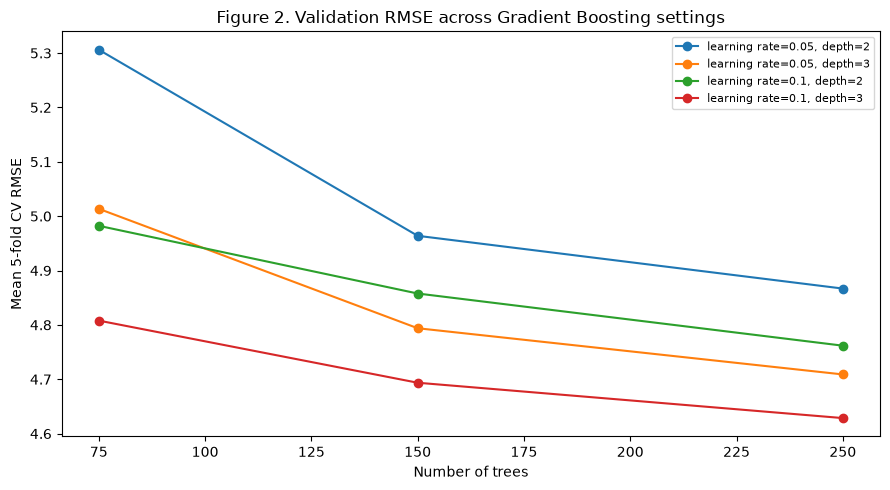

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
for (lr, depth), group in results.groupby(['param_model__learning_rate', 'param_model__max_depth']):
    group = group.sort_values('param_model__n_estimators')
    ax.plot(group['param_model__n_estimators'].astype(int), group['CV RMSE'],
            marker='o', label=f'learning rate={lr}, depth={depth}')
ax.set(title='Figure 2. Validation RMSE across Gradient Boosting settings',
       xlabel='Number of trees', ylabel='Mean 5-fold CV RMSE')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

Figure 2 compares validation RMSE across the numbers of trees, learning rates and tree depths tested. Lower points indicate better validation performance. We look for whether adding trees improves accuracy and whether those improvements become smaller as the model grows.

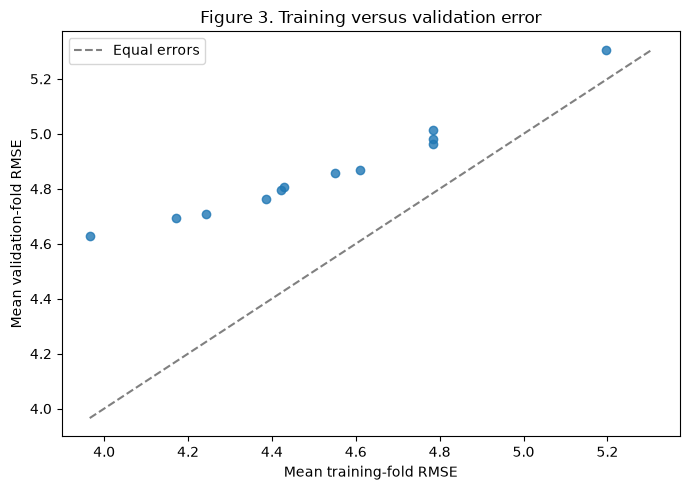

Best model training RMSE: 3.966
Best model CV RMSE: 4.629


In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(results['Train RMSE'], results['CV RMSE'], alpha=0.8)
lo = min(results['Train RMSE'].min(), results['CV RMSE'].min())
hi = max(results['Train RMSE'].max(), results['CV RMSE'].max())
ax.plot([lo, hi], [lo, hi], '--', color='gray', label='Equal errors')
ax.set(title='Figure 3. Training versus validation error',
       xlabel='Mean training-fold RMSE', ylabel='Mean validation-fold RMSE')
ax.legend(); plt.tight_layout(); plt.show()
print('Best model training RMSE:',
      round(-results.loc[search.best_index_, 'mean_train_score'], 3))
print('Best model CV RMSE:', round(-search.best_score_, 3))


### Figure 3: Results and Discussion

Figure 3 compares the training and validation RMSE for the **12 hyperparameter combinations** tested during grid search. Each point represents one combination of the number of trees, learning rate and maximum tree depth, rather than an individual school. Some points overlap because their RMSE values are similar.

Most points are above the dashed line, showing that the models performed better on their training folds than their validation folds. The best model achieved a training RMSE of **3.966** and a validation RMSE of **4.629**, suggesting some overfitting. However, this combination had the lowest validation RMSE and was therefore selected for the final model.

## Experiment: does PCA help Gradient Boosting?
Our groupmate explored Principal Component Analysis (PCA) for Linear Regression, so we also test it as an optional step for Gradient Boosting.

PCA combines the original predictors into a smaller set of components. It may reduce redundant information, but it could also remove information that decision trees find useful. We don't assume PCA will improve the model, we test it.
For a fair comparison, we use the same predictors, five cross-validation folds and Gradient Boosting settings for both versions. We standardise the encoded variables before PCA because PCA is sensitive to scale. Importantly, scaling and PCA are fitted inside each training fold using a pipeline, so information from the validation fold cannot leak into preprocessing.

We compare mean validation RMSE, then discuss whether any change is large enough to matter. The PCA version is an exploratory experiment.

In [10]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Use the settings selected earlier, changing only whether PCA is included.
best_gb_settings = {
    key.replace('model__', ''): value
    for key, value in search.best_params_.items()
}

without_pca = make_model(**best_gb_settings)

# PCA needs a dense numeric matrix. OneHotEncoder is compatible with this
# because the ColumnTransformer converts the relatively small output to dense.
with_pca = Pipeline([
    ('preprocess', preprocessor),
    ('scale', StandardScaler()),
    ('pca', PCA(n_components=0.95, svd_solver='full')),
    ('model', GradientBoostingRegressor(
        random_state=RANDOM_STATE, subsample=1.0, **best_gb_settings
    ))
])

no_pca_scores, _ = evaluate_cv(without_pca, X_train, y_train)
pca_scores, _ = evaluate_cv(with_pca, X_train, y_train)

pca_comparison = pd.DataFrame({
    'Fold': np.arange(1, 6),
    'Without PCA RMSE': no_pca_scores,
    'With PCA RMSE': pca_scores,
})
display(pca_comparison.round(3))

print(f"Without PCA — mean CV RMSE: {no_pca_scores.mean():.3f}")
print(f"With PCA    — mean CV RMSE: {pca_scores.mean():.3f}")
print(f"Change (PCA minus no PCA): {pca_scores.mean() - no_pca_scores.mean():+.3f}")
print("Lower RMSE is better.")

# Inspect how many components PCA keeps when fitted to the full training set.
# This is descriptive only; the CV results above refit PCA within each fold.
with_pca.fit(X_train, y_train)
print("Components retained (95% explained variance):",
      with_pca.named_steps['pca'].n_components_)
print("Total encoded predictors:",
      with_pca.named_steps['pca'].n_features_in_)


,Fold,Without PCA RMSE,With PCA RMSE
0,1,4.817,5.072
1,2,4.625,5.050
2,3,4.462,4.773
3,4,4.622,4.701
4,5,4.617,4.739


Without PCA — mean CV RMSE: 4.629
With PCA    — mean CV RMSE: 4.867
Change (PCA minus no PCA): +0.238
Lower RMSE is better.
Components retained (95% explained variance): 35
Total encoded predictors: 53



### PCA: Results and Discussion

Applying PCA did not improve our Gradient Boosting model. Without PCA, the mean five-fold cross-validation RMSE was **4.629**, compared with **4.867** when PCA was applied.
This was an increase of **0.238 points**, or approximately **5.1%**, meaning the PCA model was less accurate.
PCA reduced the **53 encoded predictors to 35 components**, while retaining 95% of the explained variance. However, this reduction did not improve prediction accuracy, suggesting that the original encoded features were more useful for Gradient Boosting.
We therefore kept the model without PCA for our final evaluation.


## Can we use AIC?
AIC balances model fit against complexity. For Linear Regression, counting parameters is fairly straightforward. For Gradient Boosting, it isn't: a fitted tree's leaves aren't the same as independent regression coefficients, and the trees are chosen based on earlier errors. To explore the idea, we calculate an AIC-like score, using the total number of fitted terminal leaves plus one variance parameter as a rough measure of complexity. This is not formal AIC. We must not compare it directly with the Linear Regression AIC, and even comparing boosted models this way is only exploratory. Our group's actual ranking should use CV RMSE.

In [11]:
def exploratory_aic_like(fitted_pipeline, X, y):
    predictions = fitted_pipeline.predict(X)
    rss = np.sum((np.asarray(y) - predictions) ** 2)
    gb = fitted_pipeline.named_steps['model']
    leaves = sum(tree.get_n_leaves() for tree in gb.estimators_.ravel())
    k_proxy = leaves + 1  # +1 is a rough variance parameter count
    return len(y) * np.log(max(rss / len(y), 1e-12)) + 2 * k_proxy, leaves

rows = []
for label, estimator in [('Baseline', baseline), ('CV-selected', search.best_estimator_)]:
    estimator.fit(X_train, y_train)
    score, leaves = exploratory_aic_like(estimator, X_train, y_train)
    rows.append({'Model': label, 'Fitted leaves': leaves,
                 'Exploratory AIC-like (NOT formal AIC)': score})
aic_table = pd.DataFrame(rows)
display(aic_table.round(2))
print('Do not compare these values directly with linear-regression AIC.')

,Model,Fitted leaves,Exploratory AIC-like (NOT formal AIC)
0,Baseline,795,24902.68
1,CV-selected,1969,25936.70


Do not compare these values directly with linear-regression AIC.



### AIC-like Score: Results 

The baseline model had **795 fitted leaves** and an exploratory AIC-like score of **24,902.68**, while the tuned model had **1,969 fitted leaves** and a score of **25,936.70**.
The lower AIC-like score favoured the simpler baseline model, even though the tuned model achieved a better cross-validation RMSE of **4.629**, compared with **4.753** for the baseline.
However, this is not a formal AIC calculation, because the number of tree leaves is only an approximation of model complexity. We therefore used cross-validation RMSE, rather than the AIC-like score, to select our final Gradient Boosting settings.


## Does our choice of cross-validation matter?
One issue with our dataset is that the same school can appear in several years. We check how often school IDs occur in both the original train and test splits. That is not automatically wrong, but it changes what the test tells us: we may be predicting another year for a school the model has effectively already seen.

To see whether this matters, we also use [2]GroupKFold. This keeps all rows for a school in the same fold, so validation schools are genuinely unseen during training. This is a tougher test than ordinary random CV.

In [12]:
overlap = set(train_data.school_urn) & set(test_data.school_urn)
print('Schools appearing in both original splits:', len(overlap))
print('Repeated school IDs in training:', train_data.school_urn.duplicated().sum())
group_cv = GroupKFold(n_splits=5)
group_rmse, group_train_rmse = evaluate_cv(
    make_model(**{
        'n_estimators': search.best_params_['model__n_estimators'],
        'learning_rate': search.best_params_['model__learning_rate'],
        'max_depth': search.best_params_['model__max_depth']
    }), X_train, y_train, splitter=group_cv, groups=train_data.school_urn)
print('Ordinary tuned CV RMSE:', round(-search.best_score_, 3))
print('School-grouped CV RMSE:', round(group_rmse.mean(), 3))
print('School-grouped fold scores:', np.round(group_rmse, 3))

Schools appearing in both original splits: 1547
Repeated school IDs in training: 4524
Ordinary tuned CV RMSE: 4.629
School-grouped CV RMSE: 4.941
School-grouped fold scores: [4.865 4.649 5.43  5.087 4.677]


Some schools appear in both the training and test datasets, although in different years. The school-grouped cross-validation above keeps each school entirely within one fold. Comparing its RMSE with ordinary five-fold CV shows whether predicting previously unseen schools is harder than predicting held-out school-year records. We can go one step further and hold out whole local authorities. Schools in the same area may share factors that are missing from our data. If performance gets worse when whole areas are left out, the ordinary CV result may be too optimistic for predicting schools in new areas.

,Validation method,Mean RMSE,Fold SD
0,Ordinary random 5-fold,4.629,0.126
1,School-grouped 5-fold,4.941,0.325
2,Local-authority-grouped 5-fold,4.986,0.450


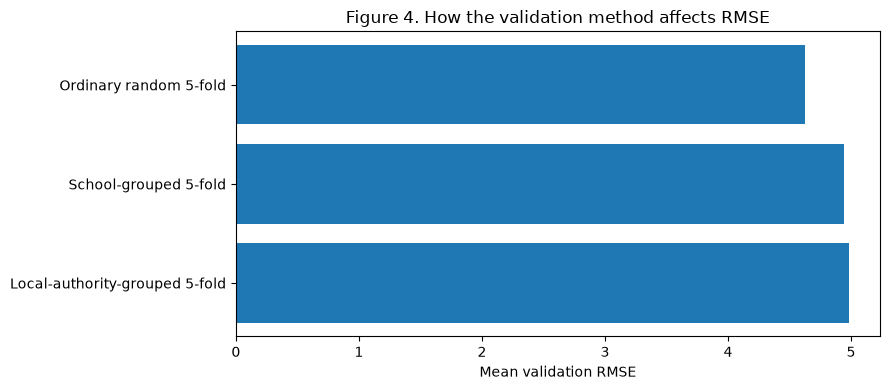

In [13]:
la_cv = GroupKFold(n_splits=5)
la_rmse, _ = evaluate_cv(search.best_estimator_, X_train, y_train,
                        splitter=la_cv, groups=train_data.new_la_code)
cv_comparison = pd.DataFrame({
    'Validation method': ['Ordinary random 5-fold', 'School-grouped 5-fold',
                          'Local-authority-grouped 5-fold'],
    'Mean RMSE': [-search.best_score_, group_rmse.mean(), la_rmse.mean()],
    'Fold SD': [results.loc[search.best_index_, 'std_test_score'] * np.sqrt(5/4),
                group_rmse.std(ddof=1), la_rmse.std(ddof=1)]
})
display(cv_comparison.round(3))
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(cv_comparison['Validation method'], cv_comparison['Mean RMSE'])
ax.invert_yaxis(); ax.set(xlabel='Mean validation RMSE',
                         title='Figure 4. How the validation method affects RMSE')
plt.tight_layout(); plt.show()


### Figure 4: Results and Discussion

Figure 4 compares the tuned model's performance under three different cross-validation methods.

Ordinary five-fold cross-validation produced the lowest mean RMSE of **4.629**. When we grouped observations by school, the RMSE increased to **4.941**, and when we grouped by local authority, it increased further to **4.986**.

We also found that **1,547 schools** appeared in both the original training and test datasets, although in different academic years.

These results suggest that ordinary cross-validation may give a slightly optimistic estimate of performance when predicting schools the model has not previously encountered. The higher grouped RMSE values indicate that predicting completely unseen schools or local authorities is more difficult.


## Which variables appear most useful?
We use permutation importance: we shuffle one variable at a time and see how much the model's prediction error increases. This is more interpretable than just counting how often a tree splits on something.

Here we use training data for a descriptive check, not as evidence of performance on new schools.

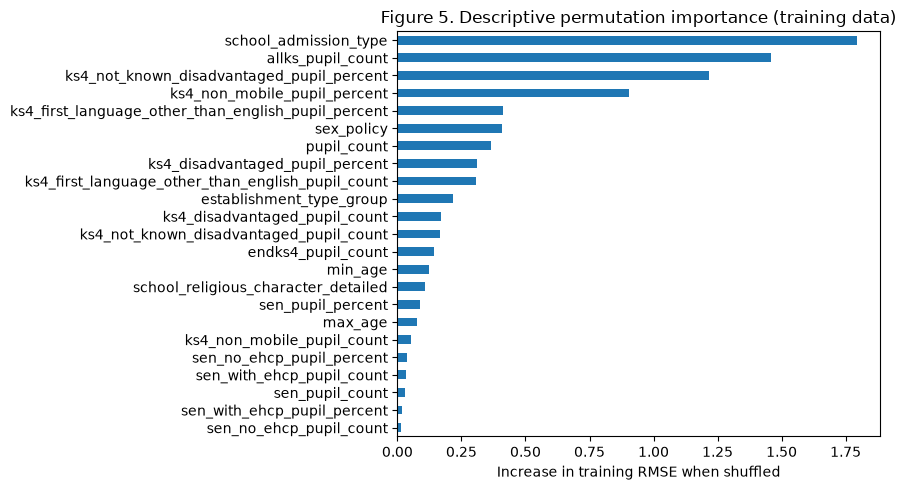

In [14]:
best_model = search.best_estimator_  # fitted on all training data by GridSearchCV
importance = permutation_importance(
    best_model, X_train, y_train, scoring='neg_root_mean_squared_error',
    n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(importance.importances_mean, index=features).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
imp.plot.barh(ax=ax)
ax.set(xlabel='Increase in training RMSE when shuffled',
       title='Figure 5. Descriptive permutation importance (training data)')
plt.tight_layout(); plt.show()

Figure 5 shows which of the 23 selected predictors have the largest effect on the fitted model's training RMSE when shuffled. Larger increases suggest the model relies more on those variables. These are descriptive, training-set importances, not causal effects, and correlated predictors can share importance.

## Final evaluation on the held-out test data
Now that we've chosen our settings, we finally use the test data. We only use it once for the final model assessment. We report test RMSE alongside MAE and $R^2$, but our group's main comparison metric is RMSE.

Test RMSE: 4.562
Test MAE:  3.562
Test R²:   0.738


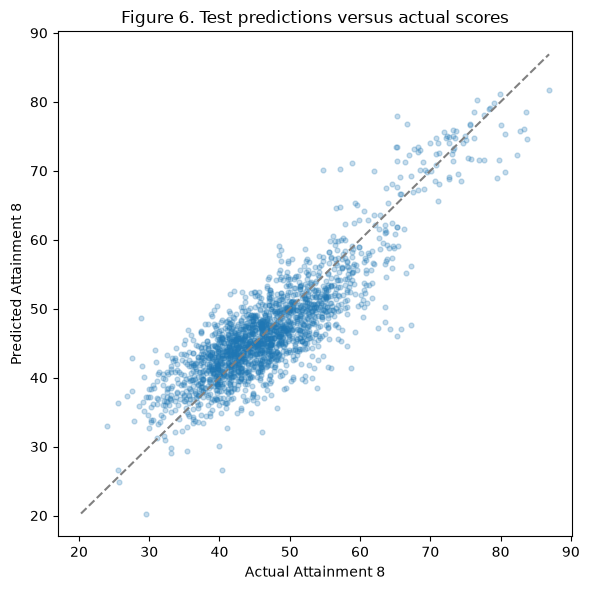

In [15]:
test_predictions = best_model.predict(X_test)
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_mae = mean_absolute_error(y_test, test_predictions)
test_r2 = r2_score(y_test, test_predictions)
print(f'Test RMSE: {test_rmse:.3f}')
print(f'Test MAE:  {test_mae:.3f}')
print(f'Test R²:   {test_r2:.3f}')
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, test_predictions, alpha=0.25, s=12)
lims = [min(y_test.min(), test_predictions.min()),
        max(y_test.max(), test_predictions.max())]
ax.plot(lims, lims, '--', color='gray')
ax.set(xlabel='Actual Attainment 8', ylabel='Predicted Attainment 8',
       title='Figure 6. Test predictions versus actual scores')
plt.tight_layout(); plt.show()


### Final Model Evaluation: Results and Discussion

The final 23-predictor Gradient Boosting model achieved a test RMSE of **4.562**, an MAE of **3.562** and an R² of **0.738**.

The RMSE of 4.562 means that the model's predictions had a root mean squared error of approximately 4.56 Attainment 8 points. The MAE of 3.562 indicates that predictions were approximately 3.56 points away from the actual scores on average.

The R² value of 0.738 shows that the model explained approximately **73.8% of the variation** in average Attainment 8 scores in the test dataset.

The test RMSE was also close to the tuned cross-validation RMSE of **4.629**, suggesting that the model performed consistently on the original held-out test records. However, the grouped cross-validation results suggest that performance may be weaker for completely unseen schools or local authorities.


## Residual Analysis
We looked at the residuals to see where our Gradient Boosting model was making errors. We first look at the training residuals to see how well the model fits the data it was trained on. We then look at the test residuals to see how well it performs on unseen data.

In [16]:

# Predictions from our fitted Gradient Boosting model
train_predictions = best_model.predict(X_train)
test_predictions = best_model.predict(X_test)

# Residuals = actual minus predicted
train_residuals = np.asarray(y_train) - train_predictions
test_residuals = np.asarray(y_test) - test_predictions

print("Training RMSE:", round(np.sqrt(np.mean(train_residuals**2)), 3))
print("Test RMSE:", round(np.sqrt(np.mean(test_residuals**2)), 3))


Training RMSE: 4.043
Test RMSE: 4.562


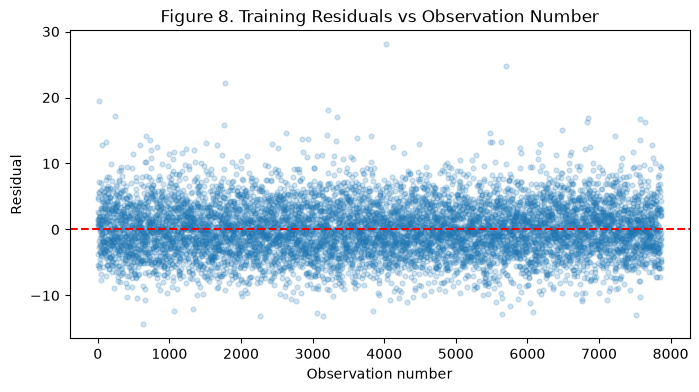

In [17]:

plt.figure(figsize=(8, 4))

plt.scatter(
    range(len(train_residuals)),
    train_residuals,
    alpha=0.2,
    s=12
)

plt.axhline(0, color='red', linestyle='--')

plt.xlabel('Observation number')
plt.ylabel('Residual')
plt.title('Figure 8. Training Residuals vs Observation Number')

plt.show()


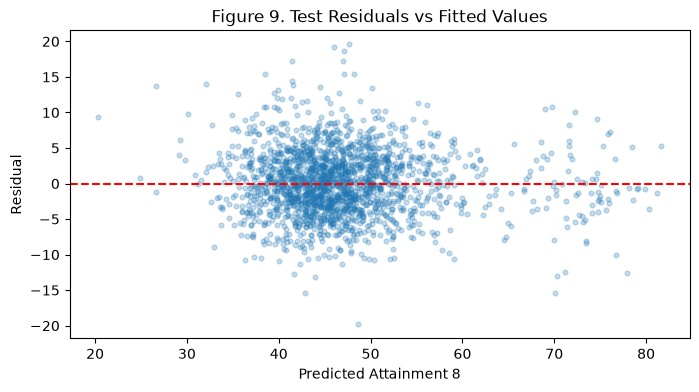

In [18]:

plt.figure(figsize=(8, 4))

plt.scatter(
    test_predictions,
    test_residuals,
    alpha=0.25,
    s=12
)

plt.axhline(0, color='red', linestyle='--')

plt.xlabel('Predicted Attainment 8')
plt.ylabel('Residual')
plt.title('Figure 9. Test Residuals vs Fitted Values')

plt.show()


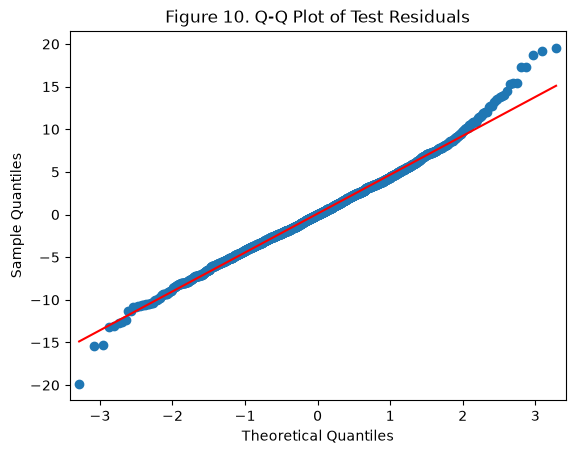

In [19]:

import statsmodels.api as sm

sm.qqplot(test_residuals, line='s')

plt.title('Figure 10. Q-Q Plot of Test Residuals')
plt.show()



### Residual Analysis: Results and Discussion

Figure 8 shows the training residuals, while Figure 9 shows the test residuals against the model's predicted Attainment 8 scores. Figure 10 uses a Q-Q plot to examine the distribution of test residuals.

The model achieved a training RMSE of **4.043**, compared with a test RMSE of **4.562**. The difference of **0.519 points** suggests that the model fits its training data better, although the increase in error on the test set is relatively modest.

The residual plots also help identify predictions with larger errors, which are not fully captured by the overall RMSE. The Q-Q plot provides an additional check for departures from a normal residual distribution. However, normally distributed residuals are not a requirement for Gradient Boosting Regression.


## Overall Conclusion and Limitations

The aim of this project was to investigate how accurately Gradient Boosting Regression could predict the average Attainment 8 score of schools in England using school and pupil characteristics.
We initially compared a model using 10 predictors with a broader model using 23 predictors. The broader model performed better, reducing the baseline five-fold cross-validation RMSE from **5.047 to 4.753**. This suggested that including additional school and pupil information improved predictive accuracy.
We then used hyperparameter tuning to improve the 23-predictor model further. The best settings were **250 trees**, a **learning rate of 0.1** and a **maximum depth of 3**, producing a cross-validation RMSE of **4.629**. We also tested PCA, but this increased the RMSE to **4.867**, so we decided not to include PCA in the final model.
Our final Gradient Boosting model achieved a **test RMSE of 4.562**, an **MAE of 3.562** and an **R² of 0.738**. This means the model explained approximately **73.8% of the variation** in Attainment 8 scores in the test data.

However, our cross-validation experiments also identified some limitations. School-grouped cross-validation produced an RMSE of **4.941**, while local-authority-grouped cross-validation produced an RMSE of **4.986**, both higher than ordinary cross-validation. This suggests that the model may be less accurate when predicting schools or local authorities that were not represented in its training data.

Overall, Gradient Boosting provided reasonably accurate predictions of average Attainment 8 scores, and both the broader predictor selection and hyperparameter tuning improved its performance. However, the model still makes prediction errors, and its performance on completely unseen schools may be weaker than the held-out test results suggest.
The final results can now be compared with our group's Linear Regression and Random Forest models, while considering differences in predictor selection and modelling approaches.

### References:
[1] scikit-learn developers (n.d.) Gradient Boosting. scikit-learn User Guide. Available at: https://scikit-learn.org/stable/modules/ensemble.html#gradient-boosting (Accessed: 1 November 2026).

[2] Scholar (n.d.) Gradient Boosting Tree. Scholar Documentation. Available at: https://scholar.hexdocs.pm/cv_gradient_boosting_tree.html (Accessed: 2 November 2026).

[3] GeeksforGeeks (n.d.) Gradient Boosting in Machine Learning. Available at: https://www.geeksforgeeks.org/machine-learning/ml-gradient-boosting/ (Accessed: 1 November 2026).